In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import string
import nltk
nltk.download('stopwords')

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from nltk.stem import SnowballStemmer
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Conv1D, GlobalMaxPooling1D, Dense, Dropout

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [ ]:
df = pd.read_csv('/content/sample_data/gojek.csv')
df.head()

,reviewId,userName,userImage,content,score,thumbsUpCount,reviewCreatedVersion,at,replyContent,repliedAt,appVersion
0,5a957f59-d97b-4ebb-81ba-76cbc950f80a,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,sangat membantu,5,0,5.14.2,2025-03-27 12:03:34,NaN,NaN,5.14.2
1,468db741-3adc-4129-b2d5-b7e47b18cf17,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,apk payah order makanan tercantum tulisan menu...,1,0,5.13.1,2025-03-27 11:59:55,"Mohon maaf atas kendalanya, Kak Vicky. Kesulit...",2025-03-27 14:08:58,5.13.1
2,0b88dcda-8b2e-4a85-b9e8-00b6f3d6cbaf,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,bagus,5,0,5.14.2,2025-03-27 11:59:47,NaN,NaN,5.14.2
3,066920d4-3f01-4f8a-9584-e6d1bd2097db,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,lama amat d fitur gofood nunggu di masak chef ...,1,0,5.14.2,2025-03-27 11:55:30,"Hai Kak @Molto srb, mohon maaf atas ketidaknya...",2025-03-27 14:06:27,5.14.2
4,4d4825c7-7e81-4c5c-ae76-8dfcd6f664de,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,tolong kalau drivernya gak mau ambil jangan di...,1,0,5.14.2,2025-03-27 11:53:53,"Hai Kak Gresela, mohon maaf atas ketidaknyaman...",2025-03-27 14:02:57,5.14.2


In [ ]:
df.isnull()

,reviewId,userName,content,score,appVersion
0,False,False,False,False,False
1,False,False,False,False,False
2,False,False,False,False,False
3,False,False,False,False,False
4,False,False,False,False,False
...,...,...,...,...,...
373495,False,False,False,False,False
373496,False,False,False,False,True
373497,False,False,False,False,True
373498,False,False,False,False,True


## Preprocessing

In [ ]:
# Get the list of columns in the DataFrame
existing_columns = df.columns.tolist()

# Define the list of columns to drop
columns_to_drop = ['reviewCreatedVersion', 'at', 'replyContent', 'repliedAt', 'userImage', 'thumbsUpCount']

# Filter out columns that are not in the DataFrame
valid_columns_to_drop = [col for col in columns_to_drop if col in existing_columns]

# Drop the valid columns
df = df.drop(columns=valid_columns_to_drop)
df = df.dropna(subset=['content'])

df.head()

,reviewId,userName,content,score,appVersion
0,5a957f59-d97b-4ebb-81ba-76cbc950f80a,Pengguna Google,sangat membantu,5,5.14.2
1,468db741-3adc-4129-b2d5-b7e47b18cf17,Pengguna Google,apk payah order makanan tercantum tulisan menu...,1,5.13.1
2,0b88dcda-8b2e-4a85-b9e8-00b6f3d6cbaf,Pengguna Google,bagus,5,5.14.2
3,066920d4-3f01-4f8a-9584-e6d1bd2097db,Pengguna Google,lama amat d fitur gofood nunggu di masak chef ...,1,5.14.2
4,4d4825c7-7e81-4c5c-ae76-8dfcd6f664de,Pengguna Google,tolong kalau drivernya gak mau ambil jangan di...,1,5.14.2


Labeling data

In [ ]:
def map_sentiment(score):
    if score <= 2:
        return 'negatif'
    elif score == 3:
        return 'netral'
    else:
        return 'positif'

df['sentiment'] = df['score'].apply(map_sentiment)
df['sentiment'].value_counts()

,count
sentiment,
positif,262899
negatif,95324
netral,15272


Balancing

In [ ]:
min_count = df['sentiment'].value_counts().min()
df_balanced = df.groupby('sentiment').apply(lambda x: x.sample(n=min_count, random_state=42)).reset_index(drop=True)
df_balanced['sentiment'].value_counts()

<ipython-input-13-2209684071>:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_balanced = df.groupby('sentiment').apply(lambda x: x.sample(n=min_count, random_state=42)).reset_index(drop=True)


,count
sentiment,
negatif,15272
netral,15272
positif,15272


stemming, lowercase

In [ ]:
!pip install swifter
!pip install PySastrawi

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 22.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for swifter: filename=swifter-1.4.0-py3-none-any.whl size=16505 sha256=9ad2b34ef855d83a0487f3b0d68fd40f56c4001cfa8db9f84b69390823d56535
  Stored in directory: /root/.cache/pip/wheels/ef/7f/bd/9bed48f078f3ee1fa75e0b29b6e0335ce1cb03a38d3443b3a3
Successfully built swifter
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 210.6/210.6 kB 4.9 MB/s eta 0:00:00


In [ ]:
import re
import string
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

factory = StemmerFactory()
stemmer = factory.create_stemmer()

def preprocess(text):
    text = text.lower()
    text = re.sub(r"\d+", "", text)  # hapus angka
    text = text.translate(str.maketrans("", "", string.punctuation))  # hapus tanda baca
    text = " ".join([stemmer.stem(word) for word in text.split()])  # stemming
    return text

df_balanced['clean_content'] = df_balanced['content'].apply(preprocess)
df_balanced[['content', 'clean_content']].head()

,content,clean_content
0,"Pembayaran denda gede bgtt cuy, gak di kasih p...",bayar denda gede bgtt cuy gak di kasih ingat h...
1,"Apikasi gk waras ,di luar akal sehat ,bego lu ...",apikasi gk waras di luar akal sehat bego lu yg...
2,KASIH FITUR PEMABATAN PESANAN LAH !!!,kasih fitur pemabatan pesan lah
3,"Apasih aplikasi nya jelek banget nget , masa b...",apasih aplikasi nya jelek banget nget masa bar...
4,Y giru,y giru


Tokenisasi

In [ ]:
X = df_balanced['clean_content'].values
y = df_balanced['sentiment'].values

tokenizer = Tokenizer(num_words=10000, oov_token='<OOV>')
tokenizer.fit_on_texts(X)
sequences = tokenizer.texts_to_sequences(X)
padded = pad_sequences(sequences, maxlen=100, padding='post')

label_map = {'negatif': 0, 'netral': 1, 'positif': 2}
y_num = np.array([label_map[label] for label in y])

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(padded, y_num, test_size=0.2, random_state=42)

In [ ]:
# Ambil indeks kata dari tokenizer
word_index = tokenizer.word_index

# Tampilkan hasil tokenisasi
for i in range(5):
    print(f"Kalimat Asli {i+1}:")
    print(df_balanced['clean_content'].iloc[i])
    print("\nToken (kata-kata):")
    print(df_balanced['clean_content'].iloc[i].split())
    print("\nSequence (angka):")
    print(sequences[i])
    print("\nPadded:")
    print(padded[i])
    print("="*50)

Kalimat Asli 1:
bayar denda gede bgtt cuy gak di kasih ingat hari rb dasar rentenir kedok aplikasi anak bangsa

Token (kata-kata):
['bayar', 'denda', 'gede', 'bgtt', 'cuy', 'gak', 'di', 'kasih', 'ingat', 'hari', 'rb', 'dasar', 'rentenir', 'kedok', 'aplikasi', 'anak', 'bangsa']

Sequence (angka):
[44, 457, 567, 1480, 3152, 16, 2, 57, 826, 89, 148, 850, 1985, 4167, 9, 326, 678]

Padded:
[  44  457  567 1480 3152   16    2   57  826   89  148  850 1985 4167
    9  326  678    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0]
Kalimat Asli 2:
apikasi gk waras di luar akal sehat bego lu yg buat apk gin sampah

Token (kata-kata):


In [ ]:
df.head(10)

,reviewId,userName,content,score,appVersion,sentiment
0,5a957f59-d97b-4ebb-81ba-76cbc950f80a,Pengguna Google,sangat membantu,5,5.14.2,positif
1,468db741-3adc-4129-b2d5-b7e47b18cf17,Pengguna Google,apk payah order makanan tercantum tulisan menu...,1,5.13.1,negatif
2,0b88dcda-8b2e-4a85-b9e8-00b6f3d6cbaf,Pengguna Google,bagus,5,5.14.2,positif
3,066920d4-3f01-4f8a-9584-e6d1bd2097db,Pengguna Google,lama amat d fitur gofood nunggu di masak chef ...,1,5.14.2,negatif
4,4d4825c7-7e81-4c5c-ae76-8dfcd6f664de,Pengguna Google,tolong kalau drivernya gak mau ambil jangan di...,1,5.14.2,negatif
5,5669f69a-403c-4d35-8235-59530eb11c10,Pengguna Google,merugikan,1,5.15.1,negatif
6,27ccf00c-9d18-45fd-9523-31826f4c3665,Pengguna Google,"Susah dapet driver, setiap dapet suka di cance...",1,NaN,negatif
7,1be3e721-6d45-4317-a3c9-0a9a88af5519,Pengguna Google,bro really? gopay later ditinjau padahal gk pe...,3,5.14.2,netral
8,d8ecfc57-fcbe-4a6b-a390-8db6550a2c75,Pengguna Google,baru ngasih THR ke ojol 50rb aja jd nya hargan...,1,5.14.2,negatif
9,83240355-637f-4c8e-bed6-6492d9d4dfd3,Pengguna Google,mantap polll,5,5.15.1,positif


# CNN MODEL


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SpatialDropout1D, Conv1D, GlobalMaxPooling1D, Dense, Dropout

model = Sequential()
model.add(Embedding(input_dim=45816, output_dim=128, input_length=100))
model.add(SpatialDropout1D(0.1))  # membantu regularisasi di level embedding
model.add(Conv1D(filters=64, kernel_size=5, activation='relu'))
model.add(GlobalMaxPooling1D())
model.add(Dense(64, activation='relu'))
model.add(Dropout(0.2))  # mengurangi overfitting
model.add(Dense(3, activation='softmax'))

model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [ ]:
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ ?                      │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d_1          │ ?                      │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(X_train, y_train_one_hot, epochs=10, batch_size=64, validation_split=0.2)

Epoch 1/10


ValueError: Attr 'Toutput_types' of 'OptionalFromValue' Op passed list of length 0 less than minimum 1.

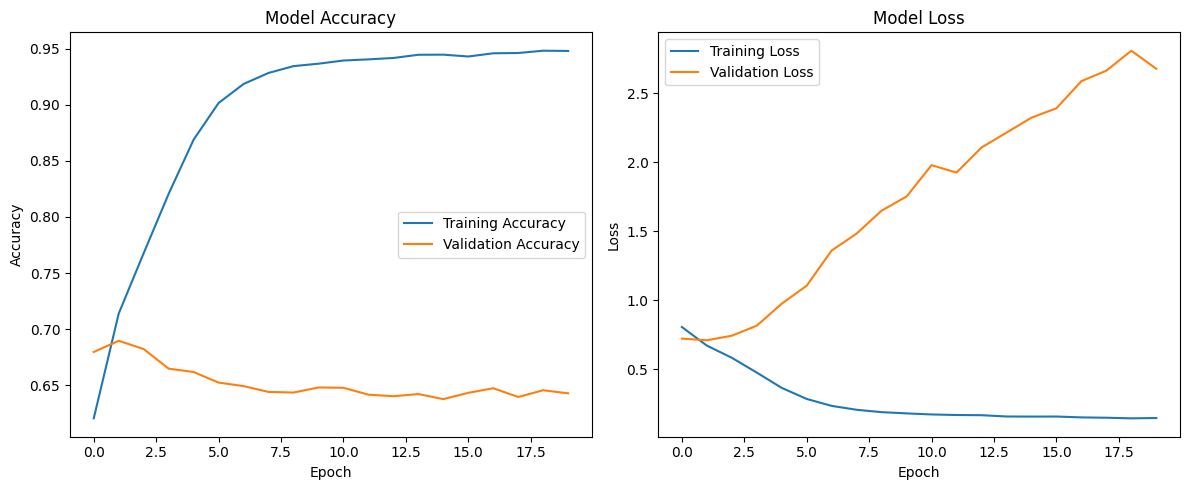

In [ ]:
# Plot akurasi
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Plot loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

287/287 ━━━━━━━━━━━━━━━━━━━━ 11s 38ms/step
              precision    recall  f1-score   support

     negatif       0.62      0.56      0.59      3064
      netral       0.51      0.51      0.51      3035
     positif       0.78      0.85      0.81      3065

    accuracy                           0.64      9164
   macro avg       0.64      0.64      0.64      9164
weighted avg       0.64      0.64      0.64      9164



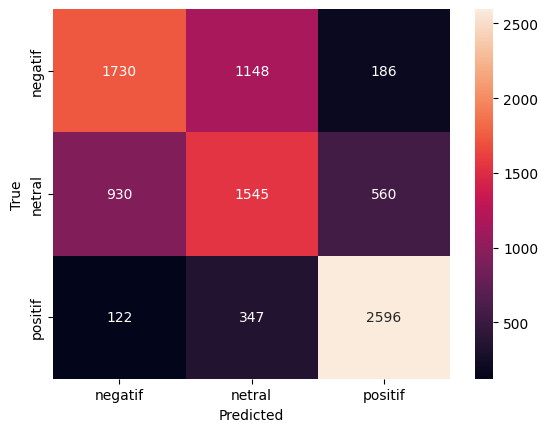

In [ ]:
y_pred = model.predict(X_test).argmax(axis=1)
print(classification_report(y_test, y_pred, target_names=label_map.keys()))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', xticklabels=label_map.keys(), yticklabels=label_map.keys())
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()